# Stage 4.4A — WOE / IV Variable Screening Diagnostics

Diagnostic evidence only. Exactly 29/29 frozen predictors remain candidates. This Notebook independently rebuilds final bins and WOE from raw Train, then examines individual signal, sparse/special-bin concentration, WOE-space correlation, family overlap, governance flags, and auxiliary linear-regression VIF. It makes no Keep/Drop, shortlist, model, performance, CV, or Holdout-risk decision.


In [1]:
from pathlib import Path
import hashlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns",40);pd.set_option("display.width",220);pd.set_option("display.max_rows",150);pd.set_option("display.float_format",lambda x:f"{x:.6f}")
TARGET="default.payment.next.month";ID_COL="ID";RANDOM_STATE=42;TEST_SIZE=.20
EXPECTED_TRAIN_HASH="bcb37af63ae7005df78e6140837594b5d650d27148b46b5d51354430ad958857";EXPECTED_TEST_HASH="d6748249f9f9fb2855746e0ed980b5013047267104090a14aa8138a700fe6f0f"
PAY_VARIABLES=["PAY_0","PAY_2","PAY_3","PAY_4","PAY_5","PAY_6"]
SUMMARY_VARIABLES=["delinquent_months","max_delinquency","severe_delinquent_months"]
CATEGORICAL_VARIABLES=["SEX","EDUCATION_GROUP","MARRIAGE_GROUP"]
CORE_CONTINUOUS=["AGE","LIMIT_BAL"];BILL_VARIABLES=[f"BILL_AMT{i}" for i in range(1,7)];PAY_AMT_VARIABLES=[f"PAY_AMT{i}" for i in range(1,7)];UTILIZATION_VARIABLES=["current_utilization","avg_utilization","max_utilization"]
PREDICTORS=PAY_VARIABLES+SUMMARY_VARIABLES+CATEGORICAL_VARIABLES+CORE_CONTINUOUS+BILL_VARIABLES+PAY_AMT_VARIABLES+UTILIZATION_VARIABLES
FAMILY_BY_PREDICTOR={**{v:"PAY" for v in PAY_VARIABLES},**{v:"Delinquency Summary" for v in SUMMARY_VARIABLES},**{v:"Demographic Categorical" for v in CATEGORICAL_VARIABLES},"AGE":"Demographic / Capacity","LIMIT_BAL":"Demographic / Capacity",**{v:"BILL" for v in BILL_VARIABLES},**{v:"PAY_AMT" for v in PAY_AMT_VARIABLES},**{v:"Utilization" for v in UTILIZATION_VARIABLES}}
GOVERNANCE_VARIABLES={"AGE","SEX","EDUCATION_GROUP","MARRIAGE_GROUP"}
assert len(PREDICTORS)==29 and len(set(PREDICTORS))==29 and list(FAMILY_BY_PREDICTOR)==PREDICTORS
FAMILY_GROUPS={"PAY / Delinquency":PAY_VARIABLES+SUMMARY_VARIABLES,"PAY_AMT":PAY_AMT_VARIABLES,"LIMIT / BILL / Utilization":["LIMIT_BAL"]+BILL_VARIABLES+UTILIZATION_VARIABLES,"Demographics":["AGE","SEX","EDUCATION_GROUP","MARRIAGE_GROUP"]}
def locate_root():
 for c in (Path.cwd().resolve(),*Path.cwd().resolve().parents):
  if (c/"data/raw/UCI_Credit_Card.csv").is_file():return c
 raise FileNotFoundError("Formal raw CSV not found")
def stable_id_hash(values):return hashlib.sha256("\n".join(str(int(v)) for v in sorted(values)).encode()).hexdigest()
project_root=locate_root();data_path=project_root/"data/raw/UCI_Credit_Card.csv"
print("Python:",sys.executable,sys.version.split()[0]);print("Project root:",project_root);print("Candidate contract:",len(PREDICTORS),"/ 29")


Python: /opt/anaconda3/bin/python 3.11.7
Project root: /Users/yu/2.工作/Risk Analysis Project
Candidate contract: 29 / 29


## 1. Frozen split replay and immediate Holdout sealing

Test participates only in row/ID/hash identity assertions. It receives no feature reproduction, binning, WOE, correlation, VIF, distribution, range, occupancy, target, or risk analysis.


In [2]:
raw_df=pd.read_csv(data_path);assert raw_df.shape==(30000,25) and raw_df[ID_COL].is_unique
train_raw,sealed_test=train_test_split(raw_df,test_size=TEST_SIZE,random_state=RANDOM_STATE,stratify=raw_df[TARGET])
train_ids=set(train_raw[ID_COL].astype(int));test_ids=set(sealed_test[ID_COL].astype(int));full_ids=set(raw_df[ID_COL].astype(int));train_hash=stable_id_hash(train_ids);test_hash=stable_id_hash(test_ids)
assert len(train_raw)==24000 and len(sealed_test)==6000 and train_ids.isdisjoint(test_ids) and train_ids|test_ids==full_ids and train_hash==EXPECTED_TRAIN_HASH and test_hash==EXPECTED_TEST_HASH
split_evidence=pd.DataFrame({"Actual":[30000,24000,6000,0,True,train_hash,test_hash]},index=["Raw rows","Train rows","Test rows","ID overlap","Full ID coverage","Train ID SHA-256","Test ID SHA-256"]);display(split_evidence)
train_original=train_raw.copy(deep=True);del sealed_test,test_ids,full_ids,raw_df
TEST_SEAL_STATUS="SEALED — Test deleted after technical row/ID/hash assertions";print(TEST_SEAL_STATUS)


,Actual
Raw rows,30000
Train rows,24000
Test rows,6000
ID overlap,0
Full ID coverage,True
Train ID SHA-256,bcb37af63ae7005df78e6140837594b5d650d27148b46b...
Test ID SHA-256,d6748249f9f9fb2855746e0ed980b5013047267104090a...


SEALED — Test deleted after technical row/ID/hash assertions


## 2. Reproduce frozen Stage 3 features and preserve source integrity

Raw PAY, BILL, PAY_AMT, AGE, LIMIT_BAL, ID, and target remain unchanged. Utilization uses the frozen zero-floor formula internally; no clipping, capping, or winsorization.


In [3]:
train_work=train_raw.copy(deep=True);raw_sources_before=train_work[PAY_VARIABLES+BILL_VARIABLES+PAY_AMT_VARIABLES+CORE_CONTINUOUS].copy(deep=True);ids_before=train_work[ID_COL].copy();target_before=train_work[TARGET].copy();index_before=train_work.index.copy()
EDUCATION_MAP={1:"Graduate School",2:"University",3:"High School",0:"Other / Unknown",4:"Other / Unknown",5:"Other / Unknown",6:"Other / Unknown"};MARRIAGE_MAP={1:"Married",2:"Single",0:"Other / Unknown",3:"Other / Unknown"}
EDUCATION_ORDER=["Graduate School","University","High School","Other / Unknown"];MARRIAGE_ORDER=["Married","Single","Other / Unknown"]
train_work["EDUCATION_GROUP"]=train_work.EDUCATION.map(EDUCATION_MAP);train_work["MARRIAGE_GROUP"]=train_work.MARRIAGE.map(MARRIAGE_MAP)
pay_matrix=train_work[PAY_VARIABLES];train_work["delinquent_months"]=(pay_matrix>0).sum(axis=1).astype(int);train_work["max_delinquency"]=pay_matrix.clip(lower=0).max(axis=1).astype(int);train_work["severe_delinquent_months"]=(pay_matrix>=2).sum(axis=1).astype(int)
assert (train_work.LIMIT_BAL>0).all();nbill=train_work[BILL_VARIABLES].clip(lower=0);train_work["current_utilization"]=nbill.BILL_AMT1/train_work.LIMIT_BAL;train_work["avg_utilization"]=nbill.mean(axis=1)/train_work.LIMIT_BAL;train_work["max_utilization"]=nbill.max(axis=1)/train_work.LIMIT_BAL
assert len(train_work)==24000 and train_work.index.equals(index_before) and train_work[ID_COL].equals(ids_before) and train_work[TARGET].equals(target_before) and train_work[ID_COL].is_unique
pd.testing.assert_frame_equal(train_work[PAY_VARIABLES+BILL_VARIABLES+PAY_AMT_VARIABLES+CORE_CONTINUOUS],raw_sources_before,check_exact=True)
assert train_work[SUMMARY_VARIABLES+CATEGORICAL_VARIABLES+UTILIZATION_VARIABLES].notna().all().all() and np.isfinite(train_work[UTILIZATION_VARIABLES]).all().all() and (train_work[UTILIZATION_VARIABLES]>=0).all().all() and (train_work[UTILIZATION_VARIABLES]>1).any().all()
TOTAL_GOOD=int((train_work[TARGET]==0).sum());TOTAL_BAD=int((train_work[TARGET]==1).sum());assert (TOTAL_GOOD,TOTAL_BAD)==(18691,5309)
display(pd.DataFrame({"Result":["PASS — 24,000 rows; ID/order/target unchanged","PASS — raw PAY/BILL/PAY_AMT/AGE/LIMIT unchanged","PASS — frozen categories and delinquency summaries reproduced","PASS — frozen utilization exact; >1 retained","PASS — no clipping/capping/winsorization"]},index=["Rows","Raw sources","Stage 3 groups/summaries","Utilization","Transform exclusions"]))


,Result
Rows,"PASS — 24,000 rows; ID/order/target unchanged"
Raw sources,PASS — raw PAY/BILL/PAY_AMT/AGE/LIMIT unchanged
Stage 3 groups/summaries,PASS — frozen categories and delinquency summa...
Utilization,PASS — frozen utilization exact; >1 retained
Transform exclusions,PASS — no clipping/capping/winsorization


## 3. Reproduce frozen Stage 4.2 and Stage 4.3 bins

The following helpers are deterministic, target/Test independent, and implement only the approved final rules. No smoothing or re-binning occurs.


In [4]:
PAY_DOMAIN=set(range(-2,9));PAY0_MAP={-2:"[-2,-1,0]",-1:"[-2,-1,0]",0:"[-2,-1,0]",1:"[1]",2:"[2+]",3:"[2+]",4:"[2+]",5:"[2+]",6:"[2+]",7:"[2+]",8:"[2+]"};PAYL_MAP={-2:"[-2,-1,0,1]",-1:"[-2,-1,0,1]",0:"[-2,-1,0,1]",1:"[-2,-1,0,1]",2:"[2]",3:"[3+]",4:"[3+]",5:"[3+]",6:"[3+]",7:"[3+]",8:"[3+]"}
def finite(x,name):
 if pd.isna(x) or not isinstance(x,(int,float,np.integer,np.floating)) or not np.isfinite(float(x)):raise ValueError(f"{name}: invalid input")
 return float(x)
def map_pay(x,v):
 z=int(finite(x,v));assert z==float(x)
 if z not in PAY_DOMAIN:raise ValueError(f"{v}: outside approved PAY domain")
 return (PAY0_MAP if v=="PAY_0" else PAYL_MAP)[z]
def map_summary(x,v):
 z=int(finite(x,v));maps={"delinquent_months":{0:"0",1:"1",2:"2",3:"3",4:"4+",5:"4+",6:"4+"},"max_delinquency":{0:"0",1:"1",2:"2",3:"3+",4:"3+",5:"3+",6:"3+",7:"3+",8:"3+"},"severe_delinquent_months":{0:"0",1:"1",2:"2",3:"3",4:"4+",5:"4+",6:"4+"}}
 if z not in maps[v]:raise ValueError(f"{v}: invalid domain")
 return maps[v][z]
def map_age(x):
 z=finite(x,"AGE");return "<=25" if z<=25 else "26–35" if z<=35 else "36–49" if z<=49 else "50+"
def map_limit(x):
 z=finite(x,"LIMIT_BAL");return "<=30k" if z<=30000 else "(30k,140k]" if z<=140000 else "(140k,240k]" if z<=240000 else ">240k"
def map_bill(x):
 z=finite(x,"BILL");return "Negative" if z<0 else "Zero" if z==0 else "(0,10k]" if z<=10000 else "(10k,40k]" if z<=40000 else ">40k"
def map_payment(x):
 z=finite(x,"PAY_AMT")
 if z<0:raise ValueError("negative PAY_AMT")
 return "0" if z==0 else "(0,5k]" if z<=5000 else "(5k,20k]" if z<=20000 else ">20k"
def map_util(x):
 z=finite(x,"utilization")
 if z<0:raise ValueError("negative utilization")
 return "0" if z==0 else "(0,0.2]" if z<=.2 else "(0.2,0.6]" if z<=.6 else "(0.6,1]" if z<=1 else ">1"
ORDERS={"PAY_0":["[-2,-1,0]","[1]","[2+]"],**{v:["[-2,-1,0,1]","[2]","[3+]"] for v in PAY_VARIABLES[1:]},"delinquent_months":["0","1","2","3","4+"],"max_delinquency":["0","1","2","3+"],"severe_delinquent_months":["0","1","2","3","4+"],"SEX":["1","2"],"EDUCATION_GROUP":EDUCATION_ORDER,"MARRIAGE_GROUP":MARRIAGE_ORDER,"AGE":["<=25","26–35","36–49","50+"],"LIMIT_BAL":["<=30k","(30k,140k]","(140k,240k]",">240k"],**{v:["Negative","Zero","(0,10k]","(10k,40k]",">40k"] for v in BILL_VARIABLES},**{v:["0","(0,5k]","(5k,20k]",">20k"] for v in PAY_AMT_VARIABLES},**{v:["0","(0,0.2]","(0.2,0.6]","(0.6,1]",">1"] for v in UTILIZATION_VARIABLES}}
MAPPERS={**{v:(lambda x,v=v:map_pay(x,v)) for v in PAY_VARIABLES},**{v:(lambda x,v=v:map_summary(x,v)) for v in SUMMARY_VARIABLES},"SEX":lambda x:str(int(finite(x,"SEX"))),"EDUCATION_GROUP":lambda x:x,"MARRIAGE_GROUP":lambda x:x,"AGE":map_age,"LIMIT_BAL":map_limit,**{v:map_bill for v in BILL_VARIABLES},**{v:map_payment for v in PAY_AMT_VARIABLES},**{v:map_util for v in UTILIZATION_VARIABLES}}
assert list(ORDERS)==PREDICTORS and list(MAPPERS)==PREDICTORS
BIN_COLUMNS=[]
for v in PREDICTORS:
 c=f"{v}_BIN";labels=train_work[v].map(MAPPERS[v]);train_work[c]=pd.Categorical(labels,categories=ORDERS[v],ordered=True);BIN_COLUMNS.append(c);assert train_work[c].notna().all() and train_work[v].map(MAPPERS[v]).tolist()==labels.tolist()
assert len(BIN_COLUMNS)==29 and len(set(BIN_COLUMNS))==29 and train_work[ID_COL].equals(ids_before) and train_work[TARGET].equals(target_before)
pd.testing.assert_frame_equal(train_work[PAY_VARIABLES+BILL_VARIABLES+PAY_AMT_VARIABLES+CORE_CONTINUOUS],raw_sources_before,check_exact=True)
print("PASS — exactly 29 frozen bin columns; mappings deterministic; source integrity retained.")


PASS — exactly 29 frozen bin columns; mappings deterministic; source integrity retained.


## 4. Rebuild 29 final WOE/IV tables and construct the 24,000×29 WOE matrix

Only final frozen-bin IV is used. WOE is `ln(DistGood / DistBad)`; positive WOE is relatively safer. Stage 4.5 will consume WOE predictors, so redundancy is examined primarily in the representation entering that future model. WOE correlation measures similarity in risk representation, not equality of raw values.


In [5]:
EXPECTED_FINAL_IV={"PAY_0":.872145621429,"PAY_2":.548098696196,"PAY_3":.414433849225,"PAY_4":.359543102661,"PAY_5":.327106490815,"PAY_6":.288165668499,"delinquent_months":.871421079861,"max_delinquency":.794582506999,"severe_delinquent_months":.846474512620,"SEX":.011049354693,"EDUCATION_GROUP":.036380079009,"MARRIAGE_GROUP":.004702252234,"AGE":.020428857210,"LIMIT_BAL":.190444892886,"BILL_AMT1":.015030576031,"BILL_AMT2":.013563868019,"BILL_AMT3":.011575527611,"BILL_AMT4":.013016361921,"BILL_AMT5":.016778116821,"BILL_AMT6":.015700367798,"PAY_AMT1":.175537864049,"PAY_AMT2":.151113586876,"PAY_AMT3":.121957912222,"PAY_AMT4":.088405981704,"PAY_AMT5":.075093140327,"PAY_AMT6":.079904481549,"current_utilization":.075545965143,"avg_utilization":.121261375406,"max_utilization":.089296728682}
final_woe_tables={};final_iv={};woe_matrix=pd.DataFrame(index=train_work.index)
for v in PREDICTORS:
 c=f"{v}_BIN";g=train_work.groupby(c,observed=True)[TARGET].agg(Count="size",Bad="sum").loc[ORDERS[v]];g["Good"]=g.Count-g.Bad;table=g.reset_index().rename(columns={c:"Final Bin"});table["% Train"]=table.Count/24000;table["Default Rate"]=table.Bad/table.Count;table["Dist Good"]=table.Good/TOTAL_GOOD;table["Dist Bad"]=table.Bad/TOTAL_BAD;table["WOE"]=np.log(table["Dist Good"]/table["Dist Bad"]);table["IV Contribution"]=(table["Dist Good"]-table["Dist Bad"])*table.WOE
 assert_ok=(table.Count==table.Good+table.Bad).all() and int(table.Count.sum())==24000 and int(table.Good.sum())==18691 and int(table.Bad.sum())==5309 and np.isclose(table["Dist Good"].sum(),1) and np.isclose(table["Dist Bad"].sum(),1) and (table.Good>0).all() and (table.Bad>0).all() and np.isfinite(table[["WOE","IV Contribution"]]).all().all();assert assert_ok
 total=float(table["IV Contribution"].sum());assert np.isclose(total,EXPECTED_FINAL_IV[v],atol=5e-12,rtol=0),(v,total);final_woe_tables[v]=table;final_iv[v]=total;lookup=table.set_index("Final Bin").WOE;woe_matrix[v]=train_work[c].map(lookup).astype(float)
 print(v,"Final IV",f"{total:.12f}");display(table)
assert woe_matrix.shape==(24000,29) and woe_matrix.columns.tolist()==PREDICTORS and woe_matrix.index.equals(train_work.index) and not woe_matrix.columns.duplicated().any() and woe_matrix.notna().all().all() and np.isfinite(woe_matrix.to_numpy()).all()
woe_matrix_rerun=pd.DataFrame({v:train_work[f"{v}_BIN"].map(final_woe_tables[v].set_index("Final Bin").WOE).astype(float) for v in PREDICTORS},index=train_work.index);pd.testing.assert_frame_equal(woe_matrix,woe_matrix_rerun,check_exact=True)
assert all(set(woe_matrix[v].unique())<=set(final_woe_tables[v].WOE) for v in PREDICTORS)
matrix_evidence=pd.DataFrame({"Result":[woe_matrix.shape,woe_matrix.columns.tolist()==PREDICTORS,woe_matrix.isna().sum().sum(),bool(np.isfinite(woe_matrix).all().all()),train_work[ID_COL].is_unique,train_work[TARGET].equals(target_before),"PASS — exact rerun"]},index=["Shape","Fixed order","Missing","Finite","Unique IDs","Target unchanged","Determinism"]);display(matrix_evidence)


PAY_0 Final IV 0.872145621429


,Final Bin,Count,Bad,Good,% Train,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,"[-2,-1,0]",18506,2540,15966,0.771083,0.137253,0.854208,0.478433,0.579659,0.217821
1,[1],3000,1031,1969,0.125000,0.343667,0.105345,0.194199,-0.611642,0.054347
2,[2+],2494,1738,756,0.103917,0.696872,0.040447,0.327369,-2.091088,0.599978


PAY_2 Final IV 0.548098696196


,Final Bin,Count,Bad,Good,% Train,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,"[-2,-1,0,1]",20473,3329,17144,0.853042,0.162604,0.917233,0.627048,0.380338,0.110368
1,[2],3145,1749,1396,0.131042,0.556121,0.074688,0.329441,-1.484072,0.378071
2,[3+],382,231,151,0.015917,0.604712,0.008079,0.043511,-1.683777,0.059660


PAY_3 Final IV 0.414433849225


...

avg_utilization Final IV 0.121261375406


,Final Bin,Count,Bad,Good,% Train,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,0,771,276,495,0.032125,0.357977,0.026483,0.051987,-0.674482,0.017202
1,"(0,0.2]",10021,1649,8372,0.417542,0.164554,0.447916,0.310605,0.366085,0.050268
2,"(0.2,0.6]",5820,1208,4612,0.242500,0.207560,0.246750,0.227538,0.081057,0.001557
3,"(0.6,1]",6880,1998,4882,0.286667,0.290407,0.261195,0.376342,-0.365230,0.042055
4,>1,508,178,330,0.021167,0.350394,0.017656,0.033528,-0.641330,0.010179


max_utilization Final IV 0.089296728682


,Final Bin,Count,Bad,Good,% Train,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,0,771,276,495,0.032125,0.357977,0.026483,0.051987,-0.674482,0.017202
1,"(0,0.2]",8269,1421,6848,0.344542,0.171847,0.366380,0.267659,0.313957,0.030994
2,"(0.2,0.6]",5018,960,4058,0.209083,0.191311,0.217110,0.180825,0.182874,0.006636
3,"(0.6,1]",6813,1700,5113,0.283875,0.249523,0.273554,0.320211,-0.157481,0.007348
4,>1,3129,952,2177,0.130375,0.304251,0.116473,0.179318,-0.431501,0.027118


,Result
Shape,"(24000, 29)"
Fixed order,True
Missing,0
Finite,True
Unique IDs,True
Target unchanged,True
Determinism,PASS — exact rerun


## 5. Layer 1 — individual final-IV, support, signal-concentration, and governance diagnostics

Sparse-bin flag is `Yes` only when minimum final-bin Train share is below 3%. Concentration is the largest single-bin IV contribution divided by total final IV. These are flags, not deletion rules. IV describes standalone discriminatory information, not unique information after redundancy.


In [6]:
individual_rows=[]
for v in PREDICTORS:
 t=final_woe_tables[v];largest=t.loc[t["IV Contribution"].idxmax()];minrow=t.loc[t.Count.idxmin()];iv=final_iv[v];iv_band="very weak" if iv<.02 else "weak" if iv<.10 else "moderate" if iv<.30 else "strong diagnostic signal"
 individual_rows.append({"Predictor":v,"Family":FAMILY_BY_PREDICTOR[v],"Final Bin Count":len(t),"Final IV":iv,"Minimum Bin Count":int(minrow.Count),"Minimum Bin Share":minrow["% Train"],"Maximum Absolute WOE":float(t.WOE.abs().max()),"Largest Single-bin IV Contribution":float(largest["IV Contribution"]),"Largest Single-bin IV Share of Total IV":float(largest["IV Contribution"]/iv) if iv>0 else np.nan,"Largest-contribution Bin":largest["Final Bin"],"Largest-bin Train Share":largest["% Train"],"Sparse-bin Flag":"Yes" if minrow["% Train"]<.03 else "No","Governance Review Flag":"Governance Review Flag — Human policy/model-governance consideration required before final candidate freeze." if v in GOVERNANCE_VARIABLES else "No","Notes":f"{iv_band}; diagnostic evidence only; Candidate status: Pending Human Checkpoint"})
individual_summary=pd.DataFrame(individual_rows);assert individual_summary.Predictor.tolist()==PREDICTORS and set(individual_summary.loc[individual_summary["Governance Review Flag"]!="No","Predictor"])==GOVERNANCE_VARIABLES;display(individual_summary)
print("Sparse-bin flags:",int((individual_summary["Sparse-bin Flag"]=="Yes").sum()),"of 29")
print("Governance flags:",sorted(GOVERNANCE_VARIABLES))


,Predictor,Family,Final Bin Count,Final IV,Minimum Bin Count,Minimum Bin Share,Maximum Absolute WOE,Largest Single-bin IV Contribution,Largest Single-bin IV Share of Total IV,Largest-contribution Bin,Largest-bin Train Share,Sparse-bin Flag,Governance Review Flag,Notes
0,PAY_0,PAY,3,0.872146,2494,0.103917,2.091088,0.599978,0.687933,[2+],0.103917,No,No,strong diagnostic signal; diagnostic evidence ...
1,PAY_2,PAY,3,0.548099,382,0.015917,1.683777,0.378071,0.689786,[2],0.131042,Yes,No,strong diagnostic signal; diagnostic evidence ...
2,PAY_3,PAY,3,0.414434,309,0.012875,1.631843,0.291613,0.703642,[2],0.127042,Yes,No,strong diagnostic signal; diagnostic evidence ...
3,PAY_4,PAY,3,0.359543,268,0.011167,1.793417,0.255929,0.711819,[2],0.105917,Yes,No,strong diagnostic signal; diagnostic evidence ...
4,PAY_5,PAY,3,0.327106,262,0.010917,1.773538,0.238502,0.729126,[2],0.087583,Yes,No,strong diagnostic signal; diagnostic evidence ...
5,PAY_6,PAY,3,0.288166,244,0.010167,1.957940,0.197967,0.686989,[2],0.092917,Yes,No,moderate; diagnostic evidence only; Candidate ...
6,delinquent_months,Delinquency Summary,5,0.871421,936,0.039000,1.844617,0.387887,0.445120,4+,0.086000,No,No,strong diagnostic signal; diagnostic evidence ...
7,max_delinquency,Delinquency Summary,4,0.794583,939,0.039125,1.774579,0.318457,0.400786,0,0.662333,No,No,strong diagnostic signal; diagnostic evidence ...
8,severe_delinquent_months,Delinquency Summary,5,0.846475,861,0.035875,1.949266,0.374400,0.442305,4+,0.074375,No,No,strong diagnostic signal; diagnostic evidence ...
9,SEX,Demographic Categorical,2,0.011049,9486,0.395250,0.126288,0.006525,0.590513,1,0.395250,No,Governance Review Flag — Human policy/model-go...,very weak; diagnostic evidence only; Candidate...


Sparse-bin flags: 14 of 29
Governance flags: ['AGE', 'EDUCATION_GROUP', 'MARRIAGE_GROUP', 'SEX']


## 6. Layer 2/3 — full and family WOE Pearson correlation

Pairwise correlation asks whether two WOE predictors give similar risk representations. Absolute correlation ≥0.70 is `Review`; ≥0.85 is `Strong`. Negative high-magnitude correlation is treated equally. No flagged pair implies a selection action.


In [7]:
corr_full=woe_matrix.corr(method="pearson");assert corr_full.shape==(29,29) and corr_full.index.tolist()==PREDICTORS and corr_full.columns.tolist()==PREDICTORS and np.allclose(corr_full,corr_full.T,atol=1e-12) and np.allclose(np.diag(corr_full),1,atol=1e-12) and np.isfinite(corr_full).all().all()
def structural_note(a,b):
 fa,fb=FAMILY_BY_PREDICTOR[a],FAMILY_BY_PREDICTOR[b]
 if a in SUMMARY_VARIABLES or b in SUMMARY_VARIABLES:
  return "PAY-derived delinquency summary relationship" if (a in PAY_VARIABLES+SUMMARY_VARIABLES and b in PAY_VARIABLES+SUMMARY_VARIABLES) else "Cross-family WOE overlap"
 if fa==fb=="PAY":return "Monthly PAY states / adjacent-history relationship"
 if fa==fb=="PAY_AMT":return "Monthly payment-amount family relationship"
 if fa==fb=="BILL":return "Monthly BILL family relationship"
 if a in UTILIZATION_VARIABLES and b in UTILIZATION_VARIABLES:return "Current/average/maximum utilization relationship"
 if (a=="LIMIT_BAL" and b in UTILIZATION_VARIABLES) or (b=="LIMIT_BAL" and a in UTILIZATION_VARIABLES):return "LIMIT_BAL appears in utilization denominators"
 if (a in BILL_VARIABLES and b in UTILIZATION_VARIABLES) or (b in BILL_VARIABLES and a in UTILIZATION_VARIABLES):return "Raw BILL contributes to utilization construction"
 if fa==fb:return f"Shared {fa} family"
 return "Cross-family WOE risk-representation overlap"
def pair_table(matrix,members):
 rows=[]
 for i,a in enumerate(members):
  for b in members[i+1:]:
   r=float(matrix.loc[a,b]);ar=abs(r)
   if ar>=.70:rows.append({"Predictor A":a,"Family A":FAMILY_BY_PREDICTOR[a],"Predictor B":b,"Family B":FAMILY_BY_PREDICTOR[b],"Correlation":r,"Absolute Correlation":ar,"Flag Level":"Strong" if ar>=.85 else "Review","Structural Relationship Note":structural_note(a,b)})
 return pd.DataFrame(rows,columns=["Predictor A","Family A","Predictor B","Family B","Correlation","Absolute Correlation","Flag Level","Structural Relationship Note"]).sort_values("Absolute Correlation",ascending=False).reset_index(drop=True) if rows else pd.DataFrame(columns=["Predictor A","Family A","Predictor B","Family B","Correlation","Absolute Correlation","Flag Level","Structural Relationship Note"])
high_pairs=pair_table(corr_full,PREDICTORS);family_corr={name:corr_full.loc[members,members].copy() for name,members in FAMILY_GROUPS.items()};family_pairs={name:pair_table(corr_full,members) for name,members in FAMILY_GROUPS.items()}
display(corr_full);print("Full |r|>=0.70 pairs:",len(high_pairs),"Strong |r|>=0.85:",int((high_pairs["Flag Level"]=="Strong").sum()) if len(high_pairs) else 0);display(high_pairs)
for name in FAMILY_GROUPS:
 print(name,"numeric WOE correlation matrix");display(family_corr[name]);print(name,"flagged pairs");display(family_pairs[name])


,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,delinquent_months,max_delinquency,severe_delinquent_months,SEX,EDUCATION_GROUP,MARRIAGE_GROUP,AGE,LIMIT_BAL,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,current_utilization,avg_utilization,max_utilization
PAY_0,1.000000,0.654062,0.463843,0.416041,0.394571,0.361009,0.755778,0.694909,0.692029,0.033992,0.065777,0.018927,0.048806,0.195167,0.090995,0.066773,0.061357,0.059504,0.072605,0.079872,0.259709,0.190637,0.161785,0.140970,0.118388,0.125074,0.211420,0.198552,0.166190
PAY_2,0.654062,1.000000,0.628891,0.483011,0.450784,0.405396,0.756965,0.669685,0.767043,0.043513,0.085935,0.010436,0.043513,0.231437,0.012620,0.050575,0.056644,0.051296,0.054007,0.081702,0.334053,0.156910,0.118090,0.105592,0.087784,0.094695,0.122033,0.148559,0.104838
PAY_3,0.463843,0.628891,1.000000,0.633541,0.490013,0.442766,0.733147,0.656158,0.774484,0.043803,0.083339,0.003558,0.044613,0.228149,0.035204,0.063043,0.052146,0.038161,0.044868,0.070032,0.093053,0.293519,0.151879,0.112876,0.093350,0.105817,0.091217,0.128091,0.076765
PAY_4,0.416041,0.483011,0.633541,1.000000,0.674615,0.509754,0.692928,0.596383,0.739088,0.037964,0.079486,0.007388,0.035224,0.210442,0.038715,0.063457,0.053657,0.034042,0.035970,0.064981,0.113374,0.090175,0.266856,0.129305,0.090048,0.098208,0.086385,0.128843,0.073075
PAY_5,0.394571,0.450784,0.490013,0.674615,1.000000,0.671160,0.645914,0.543918,0.693865,0.037595,0.067538,0.000466,0.034044,0.198494,0.037456,0.064318,0.052563,0.035964,0.034851,0.061035,0.127817,0.101075,0.078690,0.235053,0.097502,0.088591,0.090359,0.134338,0.070821
PAY_6,0.361009,0.405396,0.442766,0.509754,0.671160,1.000000,0.612797,0.551825,0.658541,0.033036,0.060451,0.002551,0.037952,0.195784,0.032833,0.060970,0.053594,0.027045,0.022877,0.049453,0.108563,0.109569,0.088512,0.049325,0.216128,0.102942,0.079491,0.125478,0.066461
delinquent_months,0.755778,0.756965,0.733147,0.692928,0.645914,0.612797,1.000000,0.943585,0.944882,0.043054,0.089264,0.007464,0.053274,0.275158,0.118440,0.095738,0.085569,0.067500,0.077331,0.095553,0.295018,0.254744,0.230480,0.195949,0.185477,0.164676,0.187172,0.197868,0.148009
max_delinquency,0.694909,0.669685,0.656158,0.596383,0.543918,0.551825,0.943585,1.000000,0.914702,0.045913,0.090017,0.000826,0.067651,0.282497,0.096433,0.085880,0.077000,0.060047,0.065656,0.088939,0.274099,0.243778,0.210430,0.172933,0.176702,0.149566,0.168724,0.181498,0.138625
severe_delinquent_months,0.692029,0.767043,0.774484,0.739088,0.693865,0.658541,0.944882,0.914702,1.000000,0.050056,0.105309,0.003534,0.063203,0.299524,0.031654,0.079028,0.072763,0.056577,0.060340,0.100770,0.208289,0.198601,0.172371,0.139362,0.136038,0.114088,0.146013,0.187271,0.123566
SEX,0.033992,0.043513,0.043803,0.037964,0.037595,0.033036,0.043054,0.045913,0.050056,1.000000,-0.006734,-0.026393,-0.015333,0.053793,-0.019447,-0.002339,-0.002847,-0.002315,0.007994,0.010977,-0.007069,0.002884,0.003896,0.001657,0.007208,0.020555,0.059623,0.055755,0.069811


Full |r|>=0.70 pairs: 12 Strong |r|>=0.85: 4


,Predictor A,Family A,Predictor B,Family B,Correlation,Absolute Correlation,Flag Level,Structural Relationship Note
0,delinquent_months,Delinquency Summary,severe_delinquent_months,Delinquency Summary,0.944882,0.944882,Strong,PAY-derived delinquency summary relationship
1,delinquent_months,Delinquency Summary,max_delinquency,Delinquency Summary,0.943585,0.943585,Strong,PAY-derived delinquency summary relationship
2,max_delinquency,Delinquency Summary,severe_delinquent_months,Delinquency Summary,0.914702,0.914702,Strong,PAY-derived delinquency summary relationship
3,avg_utilization,Utilization,max_utilization,Utilization,0.890213,0.890213,Strong,Current/average/maximum utilization relationship
4,current_utilization,Utilization,max_utilization,Utilization,0.783112,0.783112,Review,Current/average/maximum utilization relationship
5,PAY_3,PAY,severe_delinquent_months,Delinquency Summary,0.774484,0.774484,Review,PAY-derived delinquency summary relationship
6,current_utilization,Utilization,avg_utilization,Utilization,0.770533,0.770533,Review,Current/average/maximum utilization relationship
7,PAY_2,PAY,severe_delinquent_months,Delinquency Summary,0.767043,0.767043,Review,PAY-derived delinquency summary relationship
8,PAY_2,PAY,delinquent_months,Delinquency Summary,0.756965,0.756965,Review,PAY-derived delinquency summary relationship
9,PAY_0,PAY,delinquent_months,Delinquency Summary,0.755778,0.755778,Review,PAY-derived delinquency summary relationship


PAY / Delinquency numeric WOE correlation matrix


,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,delinquent_months,max_delinquency,severe_delinquent_months
PAY_0,1.000000,0.654062,0.463843,0.416041,0.394571,0.361009,0.755778,0.694909,0.692029
PAY_2,0.654062,1.000000,0.628891,0.483011,0.450784,0.405396,0.756965,0.669685,0.767043
PAY_3,0.463843,0.628891,1.000000,0.633541,0.490013,0.442766,0.733147,0.656158,0.774484
PAY_4,0.416041,0.483011,0.633541,1.000000,0.674615,0.509754,0.692928,0.596383,0.739088
PAY_5,0.394571,0.450784,0.490013,0.674615,1.000000,0.671160,0.645914,0.543918,0.693865
PAY_6,0.361009,0.405396,0.442766,0.509754,0.671160,1.000000,0.612797,0.551825,0.658541
delinquent_months,0.755778,0.756965,0.733147,0.692928,0.645914,0.612797,1.000000,0.943585,0.944882
max_delinquency,0.694909,0.669685,0.656158,0.596383,0.543918,0.551825,0.943585,1.000000,0.914702
severe_delinquent_months,0.692029,0.767043,0.774484,0.739088,0.693865,0.658541,0.944882,0.914702,1.000000


...

,Predictor A,Family A,Predictor B,Family B,Correlation,Absolute Correlation,Flag Level,Structural Relationship Note
0,avg_utilization,Utilization,max_utilization,Utilization,0.890213,0.890213,Strong,Current/average/maximum utilization relationship
1,current_utilization,Utilization,max_utilization,Utilization,0.783112,0.783112,Review,Current/average/maximum utilization relationship
2,current_utilization,Utilization,avg_utilization,Utilization,0.770533,0.770533,Review,Current/average/maximum utilization relationship


Demographics numeric WOE correlation matrix


,AGE,SEX,EDUCATION_GROUP,MARRIAGE_GROUP
AGE,1.000000,-0.015333,0.087162,0.048824
SEX,-0.015333,1.000000,-0.006734,-0.026393
EDUCATION_GROUP,0.087162,-0.006734,1.000000,0.110869
MARRIAGE_GROUP,0.048824,-0.026393,0.110869,1.000000


Demographics flagged pairs


,Predictor A,Family A,Predictor B,Family B,Correlation,Absolute Correlation,Flag Level,Structural Relationship Note


## SCR-01 — Full 29×29 WOE Correlation Heatmap

- **Question:** Where does pairwise WOE risk-representation overlap require Human review?
- **Why:** WOE-space overlap is the representation relevant to the future Stage 4.5 model.
- **Observed factual finding:** Printed below from the saved numeric matrix and threshold table.
- **Human decision needed:** Review redundancy and structural roles without selecting, deleting, or naming a representative.


Observed factual finding — strongest off-diagonal |r|: 0.944882 ; flagged pairs: 12


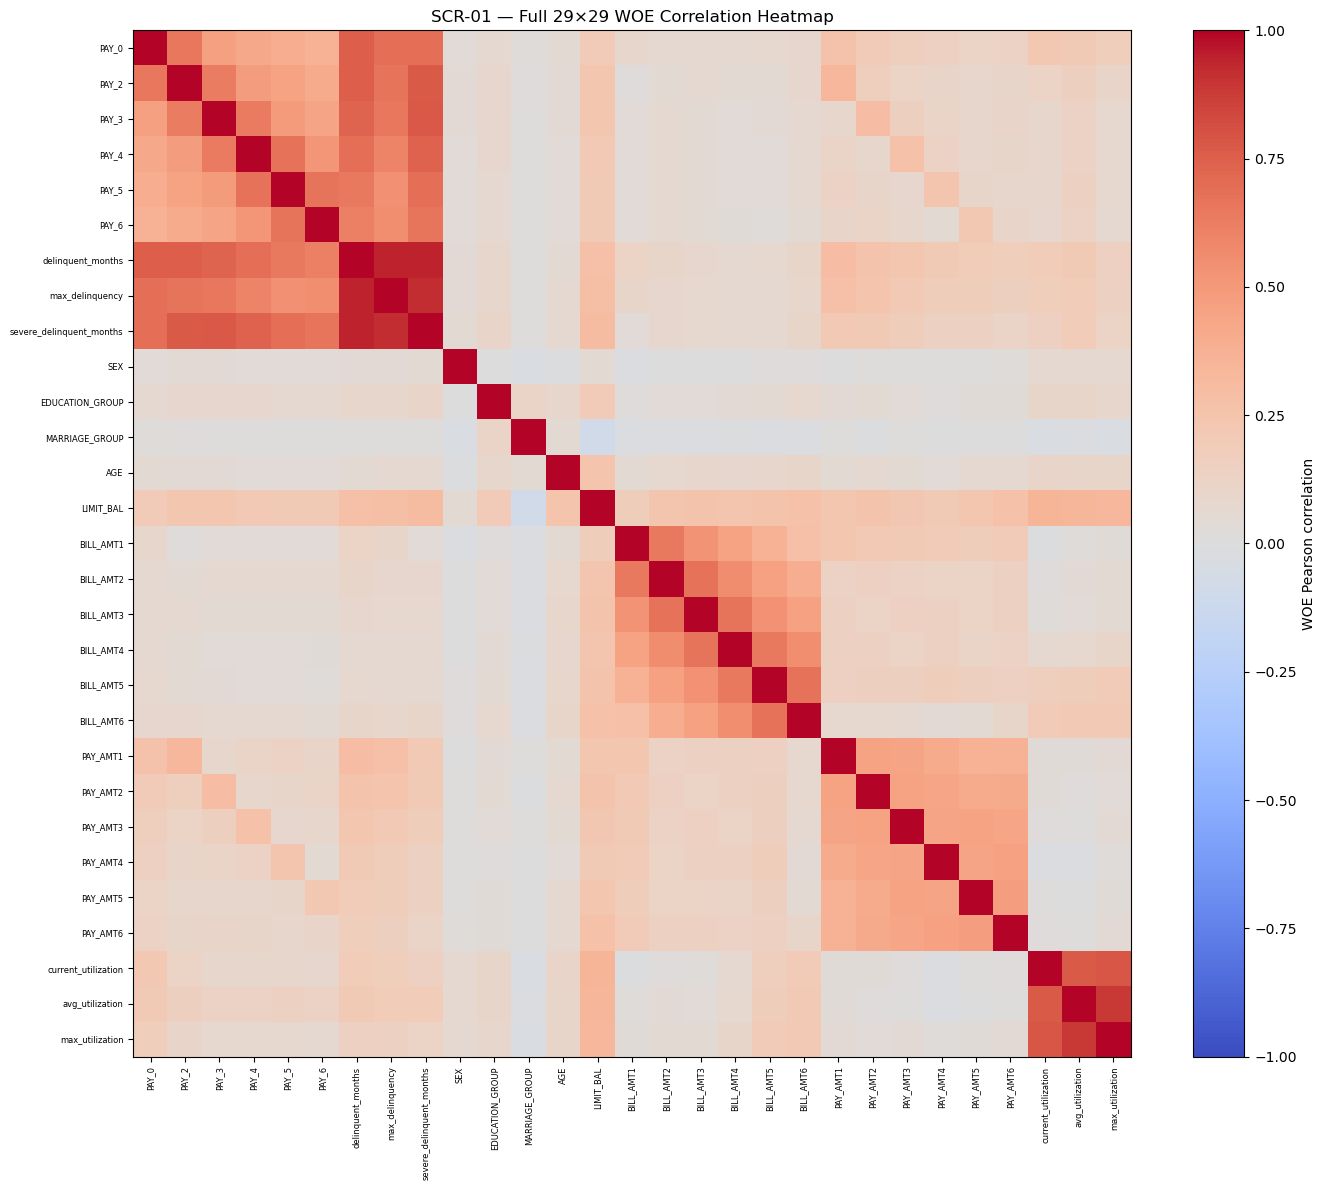

In [8]:
matrix=corr_full;mask=np.triu(np.ones(matrix.shape,dtype=bool),1);vals=np.abs(matrix.to_numpy()[mask]);print("Observed factual finding — strongest off-diagonal |r|:",f"{vals.max():.6f}","; flagged pairs:",len(high_pairs) if "FULL"=="FULL" else len(family_pairs["FULL"]))
fig,ax=plt.subplots(figsize=(14, 12));im=ax.imshow(matrix.to_numpy(),vmin=-1,vmax=1,cmap="coolwarm",aspect="auto");ax.set_xticks(range(len(matrix)),matrix.columns,rotation=90,fontsize=6);ax.set_yticks(range(len(matrix)),matrix.index,fontsize=6);ax.set_title("SCR-01 — Full 29×29 WOE Correlation Heatmap");fig.colorbar(im,ax=ax,label="WOE Pearson correlation");fig.tight_layout();plt.show();plt.close(fig)


## SCR-02 — PAY / Delinquency 9×9 WOE Correlation

- **Question:** How do monthly PAY states and structurally derived summaries overlap?
- **Why:** WOE-space overlap is the representation relevant to the future Stage 4.5 model.
- **Observed factual finding:** Printed below from the saved numeric matrix and threshold table.
- **Human decision needed:** Review redundancy and structural roles without selecting, deleting, or naming a representative.


Observed factual finding — strongest off-diagonal |r|: 0.944882 ; flagged pairs: 9


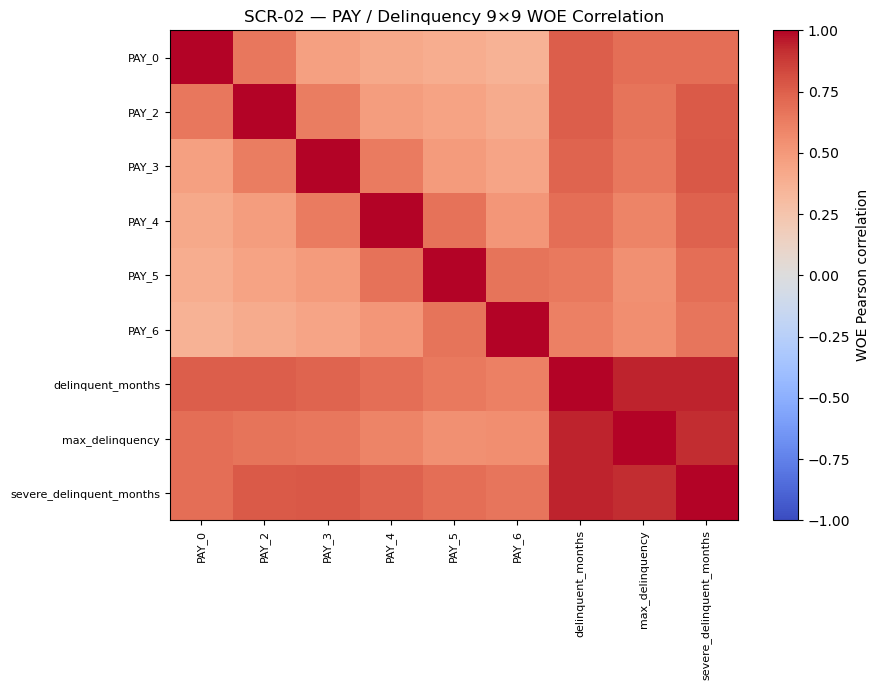

In [9]:
matrix=family_corr["PAY / Delinquency"];mask=np.triu(np.ones(matrix.shape,dtype=bool),1);vals=np.abs(matrix.to_numpy()[mask]);print("Observed factual finding — strongest off-diagonal |r|:",f"{vals.max():.6f}","; flagged pairs:",len(high_pairs) if "PAY / Delinquency"=="FULL" else len(family_pairs["PAY / Delinquency"]))
fig,ax=plt.subplots(figsize=(9, 7));im=ax.imshow(matrix.to_numpy(),vmin=-1,vmax=1,cmap="coolwarm",aspect="auto");ax.set_xticks(range(len(matrix)),matrix.columns,rotation=90,fontsize=8);ax.set_yticks(range(len(matrix)),matrix.index,fontsize=8);ax.set_title("SCR-02 — PAY / Delinquency 9×9 WOE Correlation");fig.colorbar(im,ax=ax,label="WOE Pearson correlation");fig.tight_layout();plt.show();plt.close(fig)


## SCR-03 — PAY_AMT1–6 WOE Correlation

- **Question:** How strongly do monthly payment amounts repeat WOE risk information?
- **Why:** WOE-space overlap is the representation relevant to the future Stage 4.5 model.
- **Observed factual finding:** Printed below from the saved numeric matrix and threshold table.
- **Human decision needed:** Review redundancy and structural roles without selecting, deleting, or naming a representative.


Observed factual finding — strongest off-diagonal |r|: 0.471263 ; flagged pairs: 0


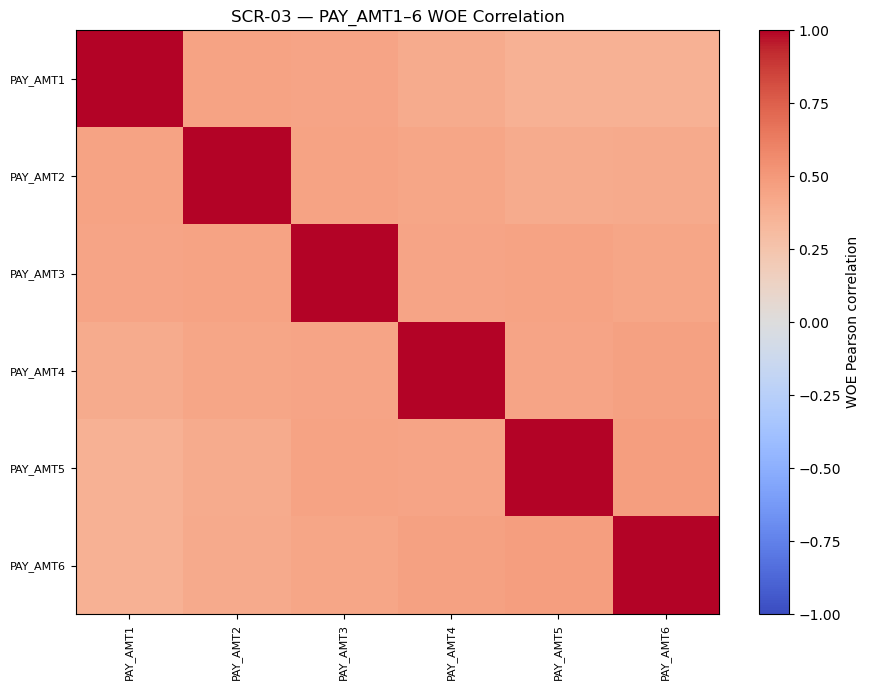

In [10]:
matrix=family_corr["PAY_AMT"];mask=np.triu(np.ones(matrix.shape,dtype=bool),1);vals=np.abs(matrix.to_numpy()[mask]);print("Observed factual finding — strongest off-diagonal |r|:",f"{vals.max():.6f}","; flagged pairs:",len(high_pairs) if "PAY_AMT"=="FULL" else len(family_pairs["PAY_AMT"]))
fig,ax=plt.subplots(figsize=(9, 7));im=ax.imshow(matrix.to_numpy(),vmin=-1,vmax=1,cmap="coolwarm",aspect="auto");ax.set_xticks(range(len(matrix)),matrix.columns,rotation=90,fontsize=8);ax.set_yticks(range(len(matrix)),matrix.index,fontsize=8);ax.set_title("SCR-03 — PAY_AMT1–6 WOE Correlation");fig.colorbar(im,ax=ax,label="WOE Pearson correlation");fig.tight_layout();plt.show();plt.close(fig)


## SCR-04 — LIMIT_BAL / BILL / Utilization WOE Correlation

- **Question:** How do capacity, monthly bills, and utilization overlap?
- **Why:** WOE-space overlap is the representation relevant to the future Stage 4.5 model.
- **Observed factual finding:** Printed below from the saved numeric matrix and threshold table.
- **Human decision needed:** Review redundancy and structural roles without selecting, deleting, or naming a representative.


Observed factual finding — strongest off-diagonal |r|: 0.890213 ; flagged pairs: 3


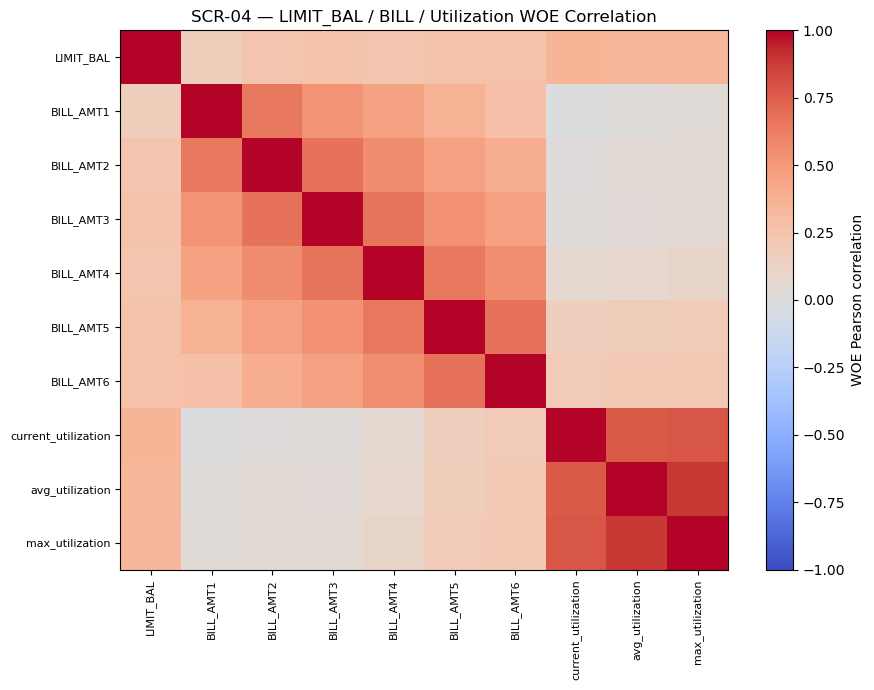

In [11]:
matrix=family_corr["LIMIT / BILL / Utilization"];mask=np.triu(np.ones(matrix.shape,dtype=bool),1);vals=np.abs(matrix.to_numpy()[mask]);print("Observed factual finding — strongest off-diagonal |r|:",f"{vals.max():.6f}","; flagged pairs:",len(high_pairs) if "LIMIT / BILL / Utilization"=="FULL" else len(family_pairs["LIMIT / BILL / Utilization"]))
fig,ax=plt.subplots(figsize=(9, 7));im=ax.imshow(matrix.to_numpy(),vmin=-1,vmax=1,cmap="coolwarm",aspect="auto");ax.set_xticks(range(len(matrix)),matrix.columns,rotation=90,fontsize=8);ax.set_yticks(range(len(matrix)),matrix.index,fontsize=8);ax.set_title("SCR-04 — LIMIT_BAL / BILL / Utilization WOE Correlation");fig.colorbar(im,ax=ax,label="WOE Pearson correlation");fig.tight_layout();plt.show();plt.close(fig)


## SCR-05 — Demographic WOE Correlation

- **Question:** What statistical overlap accompanies demographic governance review?
- **Why:** WOE-space overlap is the representation relevant to the future Stage 4.5 model.
- **Observed factual finding:** Printed below from the saved numeric matrix and threshold table.
- **Human decision needed:** Review redundancy and structural roles without selecting, deleting, or naming a representative.


Observed factual finding — strongest off-diagonal |r|: 0.110869 ; flagged pairs: 0


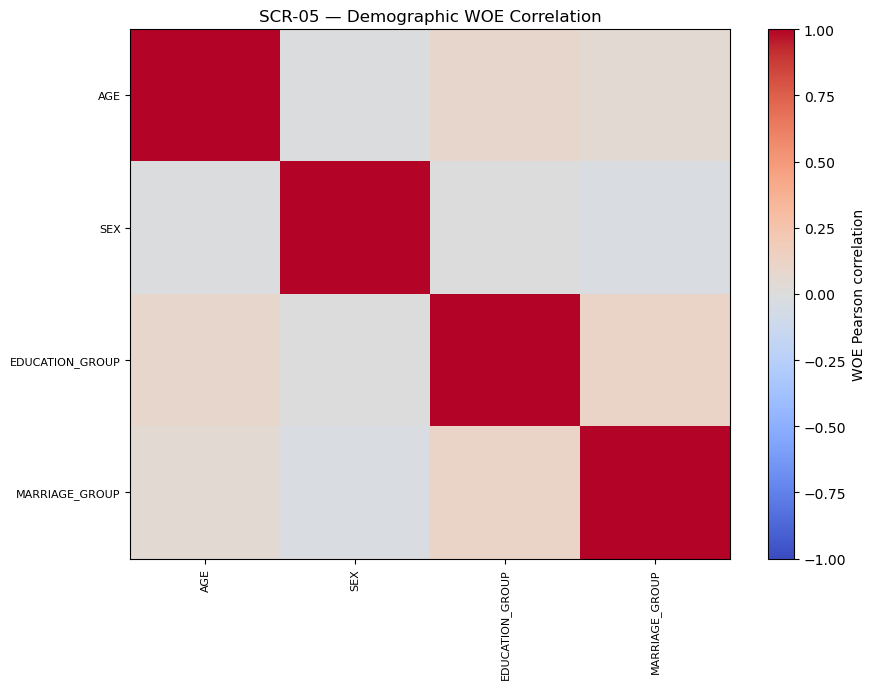

In [12]:
matrix=family_corr["Demographics"];mask=np.triu(np.ones(matrix.shape,dtype=bool),1);vals=np.abs(matrix.to_numpy()[mask]);print("Observed factual finding — strongest off-diagonal |r|:",f"{vals.max():.6f}","; flagged pairs:",len(high_pairs) if "Demographics"=="FULL" else len(family_pairs["Demographics"]))
fig,ax=plt.subplots(figsize=(9, 7));im=ax.imshow(matrix.to_numpy(),vmin=-1,vmax=1,cmap="coolwarm",aspect="auto");ax.set_xticks(range(len(matrix)),matrix.columns,rotation=90,fontsize=8);ax.set_yticks(range(len(matrix)),matrix.index,fontsize=8);ax.set_title("SCR-05 — Demographic WOE Correlation");fig.colorbar(im,ax=ax,label="WOE Pearson correlation");fig.tight_layout();plt.show();plt.close(fig)


## 12. Layer 4 — full-candidate VIF on the 24,000×29 WOE matrix

Deterministic NumPy least squares is used for 29 auxiliary OLS regressions. Each includes an intercept and the other 28 WOE predictors. Numerical tolerance for effectively perfect multicollinearity is `1−R² <= 1e-10`; such results are reported as infinite without noise, perturbation, dropping, or iterative elimination.


In [13]:
def vif_note(v):
 if v in SUMMARY_VARIABLES:return "Structurally derived from six PAY fields; assess multivariate overlap"
 if v in PAY_VARIABLES:return "Monthly PAY member with raw/summary family overlap"
 if v in BILL_VARIABLES:return "Monthly BILL family and utilization relationship"
 if v in UTILIZATION_VARIABLES:return "Shared BILL/LIMIT construction across utilization measures"
 if v in PAY_AMT_VARIABLES:return "Monthly payment-amount family"
 if v in GOVERNANCE_VARIABLES:return "Governance review flag is separate from VIF mathematics"
 return "Capacity/demographic representation in full WOE candidate set"
vif_rows=[];X=woe_matrix.to_numpy(dtype=float);VIF_TOL=1e-10
for j,v in enumerate(PREDICTORS):
 y=X[:,j];others=np.delete(X,j,axis=1);design=np.column_stack([np.ones(len(X)),others]);beta=np.linalg.lstsq(design,y,rcond=None)[0];resid=y-design@beta;sst=float(np.sum((y-y.mean())**2));sse=float(np.sum(resid**2))
 if sst<=VIF_TOL:r2=1.;vif=np.inf
 else:
  r2=1-sse/sst;den=1-r2;vif=np.inf if den<=VIF_TOL else 1/den
 flag="Infinite" if not np.isfinite(vif) else "Severe" if vif>=10 else "Review" if vif>=5 else "Low";vif_rows.append({"Predictor":v,"Family":FAMILY_BY_PREDICTOR[v],"VIF":vif,"Tolerance":0. if not np.isfinite(vif) else 1/vif,"Flag Level":flag,"Structural Note":vif_note(v),"Auxiliary R-squared":r2})
vif_table=pd.DataFrame(vif_rows);assert vif_table.Predictor.tolist()==PREDICTORS;display(vif_table)
print("VIF method: NumPy least squares, intercept included, tolerance",VIF_TOL);print("Flag counts:",vif_table["Flag Level"].value_counts().to_dict())


,Predictor,Family,VIF,Tolerance,Flag Level,Structural Note,Auxiliary R-squared
0,PAY_0,PAY,2.897468,0.345129,Low,Monthly PAY member with raw/summary family ove...,0.654871
1,PAY_2,PAY,3.825291,0.261418,Low,Monthly PAY member with raw/summary family ove...,0.738582
2,PAY_3,PAY,3.573152,0.279865,Low,Monthly PAY member with raw/summary family ove...,0.720135
3,PAY_4,PAY,3.470961,0.288105,Low,Monthly PAY member with raw/summary family ove...,0.711895
4,PAY_5,PAY,3.394307,0.294611,Low,Monthly PAY member with raw/summary family ove...,0.705389
5,PAY_6,PAY,2.575552,0.388266,Low,Monthly PAY member with raw/summary family ove...,0.611734
6,delinquent_months,Delinquency Summary,25.928051,0.038568,Severe,Structurally derived from six PAY fields; asse...,0.961432
7,max_delinquency,Delinquency Summary,17.002214,0.058816,Severe,Structurally derived from six PAY fields; asse...,0.941184
8,severe_delinquent_months,Delinquency Summary,25.142122,0.039774,Severe,Structurally derived from six PAY fields; asse...,0.960226
9,SEX,Demographic Categorical,1.012062,0.988082,Low,Governance review flag is separate from VIF ma...,0.011918


VIF method: NumPy least squares, intercept included, tolerance 1e-10
Flag counts: {'Low': 24, 'Severe': 3, 'Review': 2}


## SCR-06 — Full-candidate VIF diagnostic

- **Question:** Which WOE predictors are strongly explained by combinations of the other 28?
- **Why:** Pairwise correlation and multivariate redundancy answer different questions.
- **Observed factual finding:** Printed below in fixed registry order.
- **Human decision needed:** Review VIF together with IV, pairwise overlap, structure, support, and governance—without automated elimination.


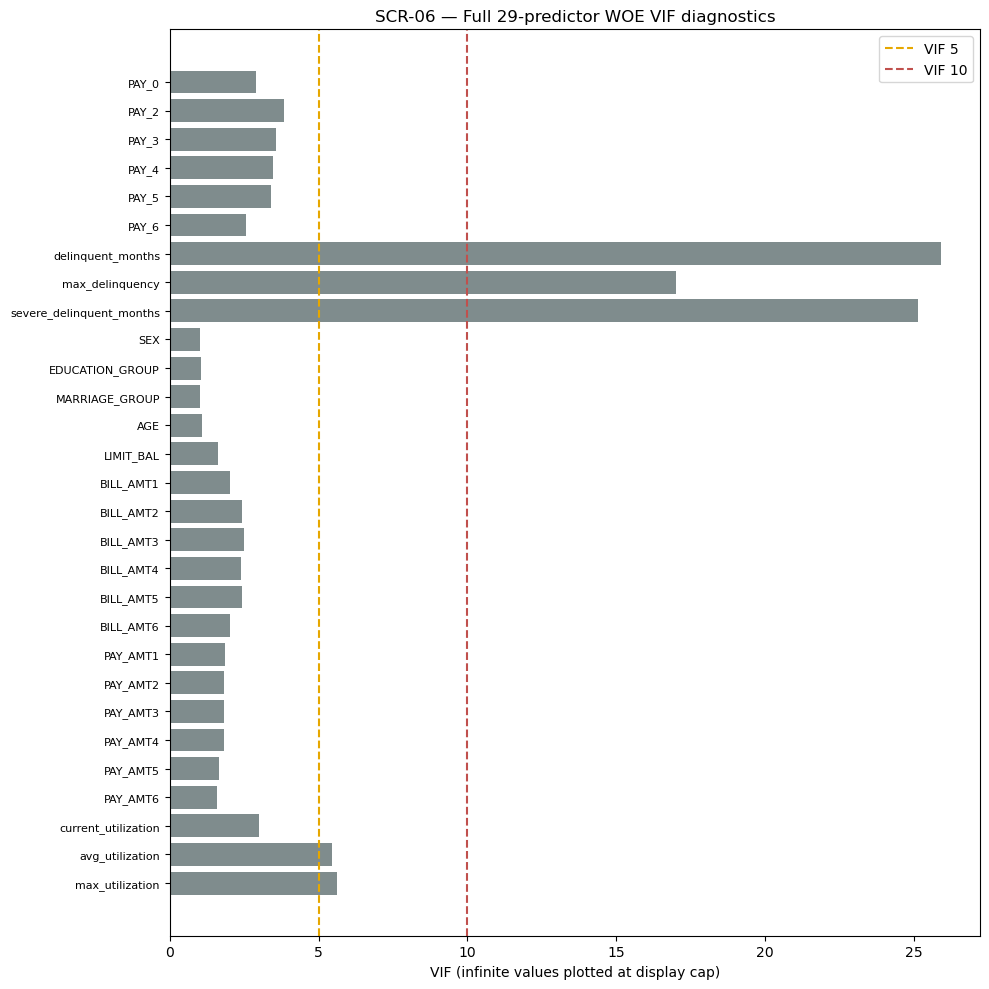

Observed factual finding — VIF flags: {'Low': 24, 'Severe': 3, 'Review': 2} ; infinite/effectively infinite: 0


In [14]:
plot_vif=vif_table.VIF.replace([np.inf,-np.inf],np.nan);finite_max=float(plot_vif.max());cap=max(12.,finite_max*1.08);values=plot_vif.fillna(cap);colors=["#7F8C8D"]*len(values);fig,ax=plt.subplots(figsize=(10,10));y=np.arange(len(PREDICTORS));ax.barh(y,values,color=colors);ax.set_yticks(y,PREDICTORS,fontsize=8);ax.invert_yaxis();ax.axvline(5,color="#E6A700",linestyle="--",label="VIF 5");ax.axvline(10,color="#C0504D",linestyle="--",label="VIF 10");ax.set_xlabel("VIF (infinite values plotted at display cap)");ax.set_title("SCR-06 — Full 29-predictor WOE VIF diagnostics");ax.legend();fig.tight_layout();plt.show();plt.close(fig)
print("Observed factual finding — VIF flags:",vif_table["Flag Level"].value_counts().to_dict(),"; infinite/effectively infinite:",int((vif_table["Flag Level"]=="Infinite").sum()))


## 14. Correlation versus VIF and family-level factual summary

Pairwise WOE correlation asks whether two individual predictors provide similar risk representations. VIF asks whether one predictor can be explained by a combination of all remaining predictors. A maximum pairwise |r| below 0.70 does not imply low multivariate redundancy. PAY summaries are deterministically derived from the six PAY fields, so multivariate overlap can exist without one extreme pair. High VIF remains diagnostic and does not authorize deletion.


In [15]:
family_rows=[]
for name,members in FAMILY_GROUPS.items():
 sub=individual_summary.set_index("Predictor").loc[members];pairs=family_pairs[name];vsub=vif_table.set_index("Predictor").loc[members];maxpair=float(pairs["Absolute Correlation"].max()) if len(pairs) else float(np.abs(family_corr[name].to_numpy()[np.triu_indices(len(members),1)]).max())
 family_rows.append({"Family Review Group":name,"Members":", ".join(members),"Final IV Range":f"{sub['Final IV'].min():.6f}–{sub['Final IV'].max():.6f}","Sparse-bin Flags":int((sub["Sparse-bin Flag"]=="Yes").sum()),"Largest Concentration Share":float(sub["Largest Single-bin IV Share of Total IV"].max()),"Strongest Pairwise |r|":maxpair,"Flagged Pairs":len(pairs),"Max VIF":float(vsub.VIF.max()),"Structural Fact":"Three summaries are deterministic PAY derivatives" if name=="PAY / Delinquency" else "Repeated monthly measurements" if name in ("PAY_AMT","LIMIT / BILL / Utilization") else "Four predictors require explicit governance review","Candidate status":"Pending Human Checkpoint"})
family_summary=pd.DataFrame(family_rows);display(family_summary)
print("PAY/delinquency questions: recent severity, historical persistence, raw/summary duplication, distinct roles — no decision.")
print("PAY_AMT questions: repetition versus distinct older-month information — no decision.")
print("LIMIT/BILL/utilization questions: weak BILL uniqueness, utilization overlap, LIMIT capacity distinction — no decision.")
print("Demographic questions: IV, sparse/special concentration, overlap, governance — no decision.")


,Family Review Group,Members,Final IV Range,Sparse-bin Flags,Largest Concentration Share,Strongest Pairwise |r|,Flagged Pairs,Max VIF,Structural Fact,Candidate status
0,PAY / Delinquency,"PAY_0, PAY_2, PAY_3, PAY_4, PAY_5, PAY_6, deli...",0.288166–0.872146,5,0.729126,0.944882,9,25.928051,Three summaries are deterministic PAY derivatives,Pending Human Checkpoint
1,PAY_AMT,"PAY_AMT1, PAY_AMT2, PAY_AMT3, PAY_AMT4, PAY_AM...",0.075093–0.175538,0,0.535633,0.471263,0,1.847939,Repeated monthly measurements,Pending Human Checkpoint
2,LIMIT / BILL / Utilization,"LIMIT_BAL, BILL_AMT1, BILL_AMT2, BILL_AMT3, BI...",0.011576–0.190445,7,0.567019,0.890213,3,5.636386,Repeated monthly measurements,Pending Human Checkpoint
3,Demographics,"AGE, SEX, EDUCATION_GROUP, MARRIAGE_GROUP",0.004702–0.036380,2,0.590513,0.110869,0,1.078982,Four predictors require explicit governance re...,Pending Human Checkpoint


PAY/delinquency questions: recent severity, historical persistence, raw/summary duplication, distinct roles — no decision.
PAY_AMT questions: repetition versus distinct older-month information — no decision.
LIMIT/BILL/utilization questions: weak BILL uniqueness, utilization overlap, LIMIT capacity distinction — no decision.
Demographic questions: IV, sparse/special concentration, overlap, governance — no decision.


## 15. Mandatory Stage 4.4A stop

All 29 predictors remain candidates. `Candidate status: Pending Human Checkpoint` applies to every predictor. No final candidate, representative, selected list, shortlist, or reduced matrix is produced. Architect/user must review PAY/delinquency, PAY_AMT, LIMIT/BILL/utilization, and demographics before any separately authorized Stage 4.4B work.


In [16]:
assert len(final_woe_tables)==29 and len(final_iv)==29 and woe_matrix.shape==(24000,29) and individual_summary.shape[0]==29 and corr_full.shape==(29,29) and vif_table.shape[0]==29
assert all(s=="Pending Human Checkpoint" for s in family_summary["Candidate status"]);CANDIDATE_COUNT_REMAINS=29
REBINNING=False;SMOOTHING=False;KEEP_DROP=False;SHORTLIST=False;IV_DELETION=False;CORRELATION_DELETION=False;VIF_DELETION=False;PREDICTIVE_LOGISTIC=False;COEFFICIENTS_PVALUES_ODDS=False;AUC_KS=False;CROSS_VALIDATION=False;TEST_RISK_ANALYSIS=False
assert CANDIDATE_COUNT_REMAINS==29 and not any([REBINNING,SMOOTHING,KEEP_DROP,SHORTLIST,IV_DELETION,CORRELATION_DELETION,VIF_DELETION,PREDICTIVE_LOGISTIC,COEFFICIENTS_PVALUES_ODDS,AUC_KS,CROSS_VALIDATION,TEST_RISK_ANALYSIS]) and TEST_SEAL_STATUS.startswith("SEALED")
display(pd.DataFrame({"Result":["PASS — 29 final WOE tables","PASS — 24,000×29 finite aligned matrix","PASS — full/family correlation and threshold pairs","PASS — 29 intercept-based auxiliary VIF regressions","PASS — SCR-01 through SCR-06","PASS — 29/29 Pending Human Checkpoint","PASS — no selection/model/performance/CV/Test risk work","PENDING — Reviewer then Architect/user Human Checkpoint"]},index=["WOE tables","WOE matrix","Correlation","VIF","Figures","Candidates","Scope","Next gate"]))
print("Stage 4.4A complete — final candidate selection pending Architect/user Human Checkpoint.")


,Result
WOE tables,PASS — 29 final WOE tables
WOE matrix,"PASS — 24,000×29 finite aligned matrix"
Correlation,PASS — full/family correlation and threshold p...
VIF,PASS — 29 intercept-based auxiliary VIF regres...
Figures,PASS — SCR-01 through SCR-06
Candidates,PASS — 29/29 Pending Human Checkpoint
Scope,PASS — no selection/model/performance/CV/Test ...
Next gate,PENDING — Reviewer then Architect/user Human C...


Stage 4.4A complete — final candidate selection pending Architect/user Human Checkpoint.


# Stage 4.4B — Human-Approved Final Candidate Freeze

## Stage 4.4A Reviewer handoff and documentation-fix closure

The independent Stage 4.4A verdict was `PASS WITH FIXES — applies to Stage 4.4A Screening Diagnostics only.` The analytical work passed. The sole defect was wording-only: the Task Report's operative sparse-bin sentence has been corrected from `<5%` to the frozen strict `<3%` rule. The original 14/29 flags remain unchanged; no re-binning, smoothing, or analytical recomputation was required solely for that correction. All Stage 4.4A cells above remain the historical diagnostic record.

Architect/user has completed the Human Checkpoint. The decisions below are Human-approved and frozen; they were not generated automatically by IV, correlation, VIF, performance, or a model.


In [17]:
FINAL_KEEP=["PAY_0","severe_delinquent_months","PAY_AMT1","PAY_AMT2","PAY_AMT3","PAY_AMT4","PAY_AMT5","PAY_AMT6","LIMIT_BAL","avg_utilization"]
FINAL_DROP=["PAY_2","PAY_3","PAY_4","PAY_5","PAY_6","delinquent_months","max_delinquency","SEX","EDUCATION_GROUP","MARRIAGE_GROUP","AGE","BILL_AMT1","BILL_AMT2","BILL_AMT3","BILL_AMT4","BILL_AMT5","BILL_AMT6","current_utilization","max_utilization"]
assert len(FINAL_KEEP)==10 and len(FINAL_DROP)==19 and len(set(FINAL_KEEP))==10 and len(set(FINAL_DROP))==19
assert set(FINAL_KEEP).isdisjoint(FINAL_DROP) and set(FINAL_KEEP)|set(FINAL_DROP)==set(PREDICTORS)
print("Human Checkpoint: COMPLETED — decisions are Human-approved, not automated.")
print("Keep (canonical order):",FINAL_KEEP)
print("Drop:",FINAL_DROP)
print("Reconciliation:",len(PREDICTORS),"-",len(FINAL_DROP),"=",len(FINAL_KEEP))


Human Checkpoint: COMPLETED — decisions are Human-approved, not automated.
Keep (canonical order): ['PAY_0', 'severe_delinquent_months', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'LIMIT_BAL', 'avg_utilization']
Drop: ['PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'delinquent_months', 'max_delinquency', 'SEX', 'EDUCATION_GROUP', 'MARRIAGE_GROUP', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'current_utilization', 'max_utilization']
Reconciliation: 29 - 19 = 10


## Frozen family decisions and evidence boundaries

- **PAY / delinquency:** keep `PAY_0` for recent/current delinquency status and `severe_delinquent_months` for serious-delinquency persistence/frequency across six months. Drop `PAY_2`–`PAY_6` for parsimonious role-based current + historical representation—not because they are weak. Drop `delinquent_months` and `max_delinquency` as individually strong but structurally redundant historical summaries; `max_delinquency` captures worst severity rather than repeated persistence. The `PAY_0`/`severe_delinquent_months` WOE correlation near 0.692 is not proof of mathematical independence.
- **PAY_AMT:** keep all six separate monthly predictors because Stage 4.4A found no pair at `|r| >= 0.70`, maximum within-family WOE correlation was about 0.471, all six VIF values were below 2, and no defensible natural month cutoff was identified. These are Stage 4.5 candidates, not guaranteed production-model variables.
- **LIMIT_BAL / BILL / utilization:** keep `LIMIT_BAL` for assigned-credit capacity and `avg_utilization` as the sustained six-month family representative. Drop all BILL variables because standalone discrimination is consistently very weak and no compelling representative exists—not because BILL is highly correlated with utilization. Drop current/max utilization in favor of the Human-approved average representation; the 0.20/0.60 bins are project bins, not industry or regulatory thresholds.
- **Demographics:** drop AGE, SEX, EDUCATION_GROUP, and MARRIAGE_GROUP to prefer behavioral and credit-exposure candidates on project parsimony/model-governance grounds. This is a project modeling decision, not a legal determination or universal prohibition.

The strict sparse-bin definition is minimum final-bin Train share `<3%`. It only asks whether apparent signal depends materially on a small final bin; it is not an automatic Drop, re-bin, smoothing, or invalidity rule. `EDUCATION_GROUP` had total IV about 0.036380; Other / Unknown had 386 Train rows (about 1.61%) and about 0.017900 IV contribution, so roughly half its IV came from a small special category. That is a caution, not proof of instability.


In [18]:
def final_rationale(v):
 if v=="PAY_0":return "Human-approved Keep: recent / most-current delinquency-status representation; not an automatic highest-IV choice."
 if v=="severe_delinquent_months":return "Human-approved Keep: historical serious-delinquency persistence/frequency across the six-month PAY history."
 if v in PAY_AMT_VARIABLES:return "Human-approved Keep: retain all six separate months for Stage 4.5 rather than impose an arbitrary month cutoff."
 if v=="LIMIT_BAL":return "Human-approved Keep: credit capacity / assigned credit-limit information with meaningful signal and low overlap."
 if v=="avg_utilization":return "Human-approved Keep: sustained six-month utilization and representative of the overlapping utilization family."
 if v in PAY_VARIABLES and v!="PAY_0":return "Human-approved Drop: parsimonious current + historical PAY representation; this monthly PAY predictor is not weak."
 if v=="delinquent_months":return "Human-approved Drop: individually strong but structurally redundant within the chosen current + historical representation."
 if v=="max_delinquency":return "Human-approved Drop: individually strong historical summary with high overlap; worst severity does not capture repeated persistence."
 if v in BILL_VARIABLES:return "Human-approved Drop: consistently very weak standalone discrimination and no compelling single BILL representative; not a utilization-correlation claim."
 if v in ["current_utilization","max_utilization"]:return "Human-approved Drop: overlapping utilization representation; avg_utilization is the frozen sustained family representative."
 if v in ["AGE","SEX","EDUCATION_GROUP","MARRIAGE_GROUP"]:return "Human-approved Drop: project parsimony/model-governance decision for the weak demographic family; not a legal conclusion."
 raise KeyError(v)
disposition_rows=[]
for v in PREDICTORS:
 keep=v in FINAL_KEEP
 disposition_rows.append({"Predictor":v,"Family":FAMILY_BY_PREDICTOR[v],"Final IV":final_iv[v],"Stage 4.4 Human Decision":"KEEP — Human-approved" if keep else "DROP — Human-approved","Final Role / Exclusion Rationale":final_rationale(v),"Stage 4.5 Candidate?":"Yes" if keep else "No"})
final_disposition=pd.DataFrame(disposition_rows)
assert final_disposition.shape==(29,6) and final_disposition.Predictor.tolist()==PREDICTORS
assert final_disposition["Stage 4.5 Candidate?"].value_counts().to_dict()=={"No":19,"Yes":10}
assert not final_disposition.astype(str).apply(lambda s:s.str.contains("Pending Human Checkpoint",case=False).any()).any()
display(final_disposition)
print("Disposition validation: 29 rows; Yes=10; No=19; no pending decision remains in the final record.")


,Predictor,Family,Final IV,Stage 4.4 Human Decision,Final Role / Exclusion Rationale,Stage 4.5 Candidate?
0,PAY_0,PAY,0.872146,KEEP — Human-approved,Human-approved Keep: recent / most-current del...,Yes
1,PAY_2,PAY,0.548099,DROP — Human-approved,Human-approved Drop: parsimonious current + hi...,No
2,PAY_3,PAY,0.414434,DROP — Human-approved,Human-approved Drop: parsimonious current + hi...,No
3,PAY_4,PAY,0.359543,DROP — Human-approved,Human-approved Drop: parsimonious current + hi...,No
4,PAY_5,PAY,0.327106,DROP — Human-approved,Human-approved Drop: parsimonious current + hi...,No
5,PAY_6,PAY,0.288166,DROP — Human-approved,Human-approved Drop: parsimonious current + hi...,No
6,delinquent_months,Delinquency Summary,0.871421,DROP — Human-approved,Human-approved Drop: individually strong but s...,No
7,max_delinquency,Delinquency Summary,0.794583,DROP — Human-approved,Human-approved Drop: individually strong histo...,No
8,severe_delinquent_months,Delinquency Summary,0.846475,KEEP — Human-approved,Human-approved Keep: historical serious-delinq...,Yes
9,SEX,Demographic Categorical,0.011049,DROP — Human-approved,Human-approved Drop: project parsimony/model-g...,No


Disposition validation: 29 rows; Yes=10; No=19; no pending decision remains in the final record.


## Exact reduced 24,000×10 WOE candidate matrix

The reduced matrix is a direct fixed-order subset of the already-verified full 24,000×29 Train WOE matrix. No bin or WOE value is re-estimated.


In [19]:
reduced_woe_matrix=woe_matrix.loc[:,FINAL_KEEP].copy()
assert reduced_woe_matrix.shape==(24000,10) and reduced_woe_matrix.columns.tolist()==FINAL_KEEP
assert reduced_woe_matrix.index.equals(woe_matrix.index) and reduced_woe_matrix.index.equals(train_work.index)
assert reduced_woe_matrix.notna().all().all() and np.isfinite(reduced_woe_matrix.to_numpy()).all()
assert not reduced_woe_matrix.columns.duplicated().any() and ID_COL not in reduced_woe_matrix and TARGET not in reduced_woe_matrix
for v in FINAL_KEEP:pd.testing.assert_series_equal(reduced_woe_matrix[v],woe_matrix[v],check_exact=True)
assert train_work[ID_COL].equals(ids_before) and train_work[TARGET].equals(target_before)
reduced_matrix_evidence=pd.DataFrame({"Result":[reduced_woe_matrix.shape,reduced_woe_matrix.columns.tolist()==FINAL_KEEP,int(reduced_woe_matrix.isna().sum().sum()),bool(np.isfinite(reduced_woe_matrix).all().all()),reduced_woe_matrix.index.equals(woe_matrix.index),train_work[ID_COL].equals(ids_before),train_work[TARGET].equals(target_before),"PASS — every column exact"]},index=["Shape","Canonical order","Missing","Finite","Row order","ID aligned","Target unchanged","Full-matrix subset"])
display(reduced_matrix_evidence)


,Result
Shape,"(24000, 10)"
Canonical order,True
Missing,0
Finite,True
Row order,True
ID aligned,True
Target unchanged,True
Full-matrix subset,PASS — every column exact


## Reduced-set WOE correlation

Pearson correlation is computed on the exact reduced WOE representation. The frozen thresholds remain Review for `0.70 <= |r| < 0.85` and Strong for `|r| >= 0.85`; signed and absolute values are retained.


In [20]:
reduced_corr=reduced_woe_matrix.corr(method="pearson")
assert reduced_corr.shape==(10,10) and reduced_corr.index.tolist()==FINAL_KEEP and reduced_corr.columns.tolist()==FINAL_KEEP
assert np.allclose(reduced_corr,reduced_corr.T,atol=1e-12) and np.allclose(np.diag(reduced_corr),1,atol=1e-12) and np.isfinite(reduced_corr).all().all()
reduced_high_pairs=pair_table(reduced_corr,FINAL_KEEP)
reduced_offdiag=np.abs(reduced_corr.to_numpy()[np.triu_indices(10,1)])
reduced_max_abs_corr=float(reduced_offdiag.max())
reduced_review_pair_count=int((reduced_high_pairs["Absolute Correlation"]>=.70).sum()) if len(reduced_high_pairs) else 0
reduced_strong_pair_count=int((reduced_high_pairs["Absolute Correlation"]>=.85).sum()) if len(reduced_high_pairs) else 0
display(reduced_corr);display(reduced_high_pairs)
print("Reduced maximum absolute off-diagonal correlation:",f"{reduced_max_abs_corr:.6f}")
print("Reduced |r|>=0.70 pairs:",reduced_review_pair_count,"; |r|>=0.85 pairs:",reduced_strong_pair_count)


,PAY_0,severe_delinquent_months,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,LIMIT_BAL,avg_utilization
PAY_0,1.000000,0.692029,0.259709,0.190637,0.161785,0.140970,0.118388,0.125074,0.195167,0.198552
severe_delinquent_months,0.692029,1.000000,0.208289,0.198601,0.172371,0.139362,0.136038,0.114088,0.299524,0.187271
PAY_AMT1,0.259709,0.208289,1.000000,0.448809,0.442652,0.398748,0.372389,0.374639,0.227599,0.025080
PAY_AMT2,0.190637,0.198601,0.448809,1.000000,0.452297,0.436578,0.404541,0.408107,0.255705,0.015174
PAY_AMT3,0.161785,0.172371,0.442652,0.452297,1.000000,0.441861,0.445683,0.431467,0.222042,0.006916
PAY_AMT4,0.140970,0.139362,0.398748,0.436578,0.441861,1.000000,0.442683,0.458867,0.201073,-0.016322
PAY_AMT5,0.118388,0.136038,0.372389,0.404541,0.445683,0.442683,1.000000,0.471263,0.230981,-0.001055
PAY_AMT6,0.125074,0.114088,0.374639,0.408107,0.431467,0.458867,0.471263,1.000000,0.273361,0.006592
LIMIT_BAL,0.195167,0.299524,0.227599,0.255705,0.222042,0.201073,0.230981,0.273361,1.000000,0.337780
avg_utilization,0.198552,0.187271,0.025080,0.015174,0.006916,-0.016322,-0.001055,0.006592,0.337780,1.000000


,Predictor A,Family A,Predictor B,Family B,Correlation,Absolute Correlation,Flag Level,Structural Relationship Note


Reduced maximum absolute off-diagonal correlation: 0.692029
Reduced |r|>=0.70 pairs: 0 ; |r|>=0.85 pairs: 0


## SCR-07 — Final 10-variable WOE correlation heatmap

- **Question:** Does the Human-approved ten-variable WOE candidate set retain any Stage 4.4 Review or Strong pairwise redundancy flag?
- **Why:** This validates the frozen list before Stage 4.5 without reopening selection.
- **Observed factual finding:** printed below from the clean-run reduced matrix.
- **Human/Architect decision needed:** determined only by the frozen conditional-stop logic after both correlation and VIF are computed.


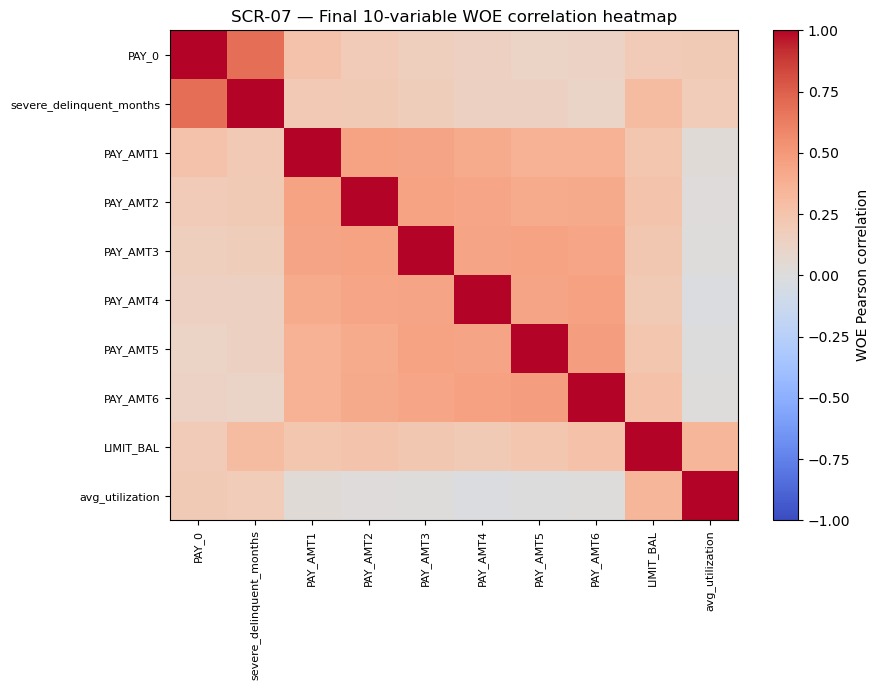

Observed factual finding — max off-diagonal |r|: 0.692029 ; Review pairs: 0 ; Strong pairs: 0


In [21]:
fig,ax=plt.subplots(figsize=(9,7));im=ax.imshow(reduced_corr.to_numpy(),cmap="coolwarm",vmin=-1,vmax=1,aspect="auto")
ax.set_xticks(range(10),FINAL_KEEP,rotation=90,fontsize=8);ax.set_yticks(range(10),FINAL_KEEP,fontsize=8)
ax.set_title("SCR-07 — Final 10-variable WOE correlation heatmap");cb=fig.colorbar(im,ax=ax);cb.set_label("WOE Pearson correlation")
fig.tight_layout();plt.show()
print("Observed factual finding — max off-diagonal |r|:",f"{reduced_max_abs_corr:.6f}","; Review pairs:",reduced_review_pair_count,"; Strong pairs:",reduced_strong_pair_count)


## Reduced-set VIF with intercept

Each candidate is regressed on an intercept plus the other nine reduced WOE predictors using the same deterministic NumPy least-squares method as Stage 4.4A. No jitter, perturbation, or removal is applied.


In [22]:
FINAL_ROLE={"PAY_0":"Current delinquency status","severe_delinquent_months":"Historical serious-delinquency persistence","PAY_AMT1":"Monthly payment amount 1","PAY_AMT2":"Monthly payment amount 2","PAY_AMT3":"Monthly payment amount 3","PAY_AMT4":"Monthly payment amount 4","PAY_AMT5":"Monthly payment amount 5","PAY_AMT6":"Monthly payment amount 6","LIMIT_BAL":"Assigned credit capacity","avg_utilization":"Sustained six-month utilization"}
reduced_vif_rows=[];XR=reduced_woe_matrix.to_numpy(dtype=float);REDUCED_VIF_TOL=1e-10
for j,v in enumerate(FINAL_KEEP):
 y=XR[:,j];others=np.delete(XR,j,axis=1);design=np.column_stack([np.ones(len(XR)),others]);beta=np.linalg.lstsq(design,y,rcond=None)[0];resid=y-design@beta;sst=float(np.sum((y-y.mean())**2));sse=float(np.sum(resid**2))
 if sst<=REDUCED_VIF_TOL:r2=1.;vif=np.inf
 else:
  r2=1-sse/sst;den=1-r2;vif=np.inf if den<=REDUCED_VIF_TOL else 1/den
 flag="Infinite" if not np.isfinite(vif) else "Severe" if vif>=10 else "Review" if vif>=5 else "Low"
 reduced_vif_rows.append({"Predictor":v,"VIF":vif,"Tolerance":0. if not np.isfinite(vif) else 1/vif,"Flag Level":flag,"Final Role":FINAL_ROLE[v]})
reduced_vif_table=pd.DataFrame(reduced_vif_rows)
assert reduced_vif_table.Predictor.tolist()==FINAL_KEEP and reduced_vif_table.shape==(10,5)
reduced_vif_flag_counts=reduced_vif_table["Flag Level"].value_counts().to_dict();reduced_max_vif=float(reduced_vif_table.VIF.max());reduced_infinite_count=int((~np.isfinite(reduced_vif_table.VIF)).sum())
display(reduced_vif_table)
print("Reduced VIF method: NumPy least squares with intercept; tolerance",REDUCED_VIF_TOL)
print("Flag counts:",reduced_vif_flag_counts,"; maximum VIF:",f"{reduced_max_vif:.6f}","; infinite/effectively infinite:",reduced_infinite_count)


,Predictor,VIF,Tolerance,Flag Level,Final Role
0,PAY_0,2.009437,0.497652,Low,Current delinquency status
1,severe_delinquent_months,2.040957,0.489966,Low,Historical serious-delinquency persistence
2,PAY_AMT1,1.502995,0.665338,Low,Monthly payment amount 1
3,PAY_AMT2,1.552006,0.644328,Low,Monthly payment amount 2
4,PAY_AMT3,1.582135,0.632057,Low,Monthly payment amount 3
5,PAY_AMT4,1.549837,0.645229,Low,Monthly payment amount 4
6,PAY_AMT5,1.533791,0.651979,Low,Monthly payment amount 5
7,PAY_AMT6,1.565398,0.638815,Low,Monthly payment amount 6
8,LIMIT_BAL,1.350414,0.740514,Low,Assigned credit capacity
9,avg_utilization,1.177133,0.849522,Low,Sustained six-month utilization


Reduced VIF method: NumPy least squares with intercept; tolerance 1e-10
Flag counts: {'Low': 10} ; maximum VIF: 2.040957 ; infinite/effectively infinite: 0


## SCR-08 — Final 10-variable VIF diagnostic

- **Question:** Is any frozen candidate jointly explained by the other nine WOE predictors at a Review, Severe, or Infinite VIF level?
- **Why:** VIF detects multivariate redundancy that pairwise correlation alone may not reveal.
- **Observed factual finding:** printed below from the clean-run reduced matrix.
- **Human/Architect decision needed:** determined by the frozen conditional-stop logic; the figure itself never removes a variable.


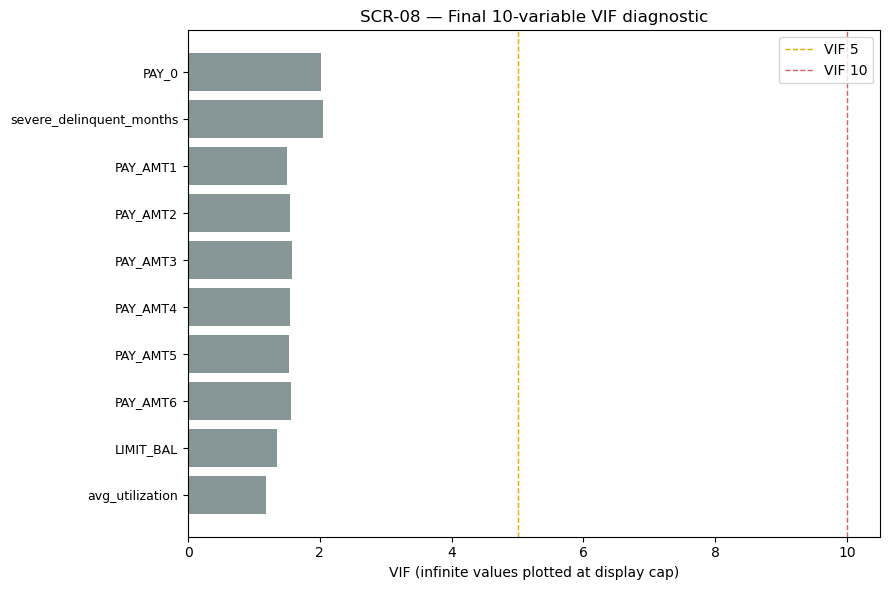

Observed factual finding — VIF flags: {'Low': 10} ; maximum: 2.040957 ; infinite/effectively infinite: 0


In [23]:
plot_reduced_vif=reduced_vif_table.VIF.replace([np.inf,-np.inf],np.nan);finite_max=float(plot_reduced_vif.max());display_cap=max(12.,finite_max*1.08);plot_values=plot_reduced_vif.fillna(display_cap)
fig,ax=plt.subplots(figsize=(9,6));ypos=np.arange(len(FINAL_KEEP));ax.barh(ypos,plot_values,color="#879696");ax.set_yticks(ypos,FINAL_KEEP,fontsize=9);ax.invert_yaxis();ax.axvline(5,color="#e6a700",ls="--",lw=1,label="VIF 5");ax.axvline(10,color="#d95f5f",ls="--",lw=1,label="VIF 10");ax.set_xlabel("VIF (infinite values plotted at display cap)");ax.set_title("SCR-08 — Final 10-variable VIF diagnostic");ax.legend();fig.tight_layout();plt.show()
print("Observed factual finding — VIF flags:",reduced_vif_flag_counts,"; maximum:",f"{reduced_max_vif:.6f}","; infinite/effectively infinite:",reduced_infinite_count)


## Conditional validation and Stage 4.5 boundary

The frozen list is not changed in response to diagnostics. Clean validation requires every reduced `|r| < 0.70` and every reduced VIF `<5`. A Review-level result requires Architect review; a Strong/Severe/Infinite result blocks final Stage 4.4 closure. No predictive Logistic, performance metric, CV, Test risk analysis, alternate subset search, or new feature engineering belongs to this Stage.


In [24]:
reduced_corr_review=bool(reduced_max_abs_corr>=.70);reduced_corr_severe=bool(reduced_max_abs_corr>=.85);reduced_vif_review=bool(np.isfinite(reduced_max_vif) and reduced_max_vif>=5);reduced_vif_severe=bool((not np.isfinite(reduced_max_vif)) or reduced_max_vif>=10)
if reduced_corr_severe or reduced_vif_severe:
 REDUCED_VALIDATION_STATUS="BLOCKED for final Stage 4.4 closure";ARCHITECT_REVIEW_REQUIRED=True;CANDIDATE_FREEZE_STATUS="NOT FROZEN — all 10 retained without automatic change"
elif reduced_corr_review or reduced_vif_review:
 REDUCED_VALIDATION_STATUS="ARCHITECT REVIEW REQUIRED";ARCHITECT_REVIEW_REQUIRED=True;CANDIDATE_FREEZE_STATUS="NOT FROZEN — all 10 temporarily retained"
else:
 REDUCED_VALIDATION_STATUS="CLEAN — no Stage 4.4 redundancy flags remain in the reduced candidate set.";ARCHITECT_REVIEW_REQUIRED=False;CANDIDATE_FREEZE_STATUS="Stage 4.4 Candidate Logistic Predictor List — FROZEN"
assert len(FINAL_KEEP)==10 and reduced_woe_matrix.shape==(24000,10) and not any(v in FINAL_KEEP for v in FINAL_DROP)
print("Conditional validation:",REDUCED_VALIDATION_STATUS)
print("Architect review required:","Yes" if ARCHITECT_REVIEW_REQUIRED else "No")
print("Candidate status:",CANDIDATE_FREEZE_STATUS)
print("Stage 4.5 boundary: candidate list only; no predictive model has been fitted.")


Conditional validation: CLEAN — no Stage 4.4 redundancy flags remain in the reduced candidate set.
Architect review required: No
Candidate status: Stage 4.4 Candidate Logistic Predictor List — FROZEN
Stage 4.5 boundary: candidate list only; no predictive model has been fitted.
